# 09 — Mô hình hồi quy Logistic: chiều BTC tháng này và S&P 500 tháng sau

## Mục tiêu và phạm vi

Notebook tái lập mô hình dự báo đang hiển thị trên dashboard Tableau (trang *Dự báo S&P 500 từ BTC*) và lưu lại toàn bộ bước tính để đối chiếu.

Bài toán là phân lớp nhị phân theo tháng:

- Biến mục tiêu $y_t = 1$ nếu phần trăm thay đổi mức S&P 500 của tháng $t+1$ lớn hơn 0, ngược lại $y_t = 0$.
- Biến giải thích duy nhất là lợi suất log của BTC trong tháng $t$: $x_t = \ln(1 + r^{BTC}_t / 100)$, với $r^{BTC}_t$ là `btc_return_pct`.

Dữ liệu lấy từ `analysis_crypto_macro_monthly.csv` (160 tháng, 01/2013–04/2026). Tháng 04/2026 không có S&P tháng sau trong bảng phân tích nên chỉ dùng để minh họa dự báo một bước.

Tập huấn luyện gồm các tháng 01/2013–12/2021, tập kiểm tra gồm các tháng 01/2022–03/2026. Mô hình chỉ được ước lượng trên tập huấn luyện; tập kiểm tra chỉ dùng để đánh giá. Mốc cơ sở là quy tắc luôn đoán "S&P 500 tăng", tức lớp chiếm đa số trong tập huấn luyện.

Kết quả là liên hệ thống kê giữa hai chuỗi, không phải quan hệ nhân quả. Phần cuối notebook kiểm tra độ vững khi đo BTC và S&P 500 theo cùng một quy ước thời điểm.

In [1]:
from pathlib import Path
import sys, json, zipfile, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm

sys.path.insert(0, str(Path.cwd() / "scripts"))
from common import ROOT, PROCESSED, TABLES, QUALITY, ensure_output_dirs, write_csv_atomic, write_json_atomic
ensure_output_dirs()
MODEL_FIG = PROCESSED / "model_figures"
MODEL_FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 180, "font.family": "DejaVu Sans"})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(MODEL_FIG / name, bbox_inches="tight")
    plt.show()
    plt.close(fig)

TRAIN_END = pd.Timestamp("2021-12-31")
TIER_CUTS = (0.60, 0.75)   # quy ước phân nhóm rủi ro dùng trên dashboard
TIER_COLORS = {"1. Thấp": "#4E79A7", "2. Trung bình": "#F28E2B", "3. Cao": "#E15759"}  # trùng màu hiển thị trên dashboard

## Chuẩn bị biến mục tiêu và biến giải thích

Bảng phân tích có lịch tháng liên tục, nên `shift(-1)` lấy đúng tháng lịch kế tiếp. Notebook kiểm tra điều kiện này trước khi tạo biến trễ. Biến mục tiêu chỉ được tạo khi có thay đổi S&P 500 của tháng sau; tháng cuối cùng vì vậy không thuộc tập huấn luyện hay kiểm tra.

In [2]:
data = pd.read_csv(TABLES / "analysis_crypto_macro_monthly.csv", parse_dates=["month"]).sort_values("month")
expected = pd.date_range(data["month"].min(), data["month"].max(), freq="ME")
assert data["month"].reset_index(drop=True).equals(pd.Series(expected, name="month")), "Lịch tháng không liên tục"

df = data[["month", "btc_price_usd", "btc_return_pct", "sp500_return_pct"]].copy().reset_index(drop=True)
df["x_log_btc"] = np.log1p(df["btc_return_pct"] / 100)
df["sp500_next_return_pct"] = df["sp500_return_pct"].shift(-1)
df["y_sp500_next_up"] = (df["sp500_next_return_pct"] > 0).astype(float).where(df["sp500_next_return_pct"].notna())
df["split"] = np.where(df["month"] <= TRAIN_END, "train", "test")

model_df = df.dropna(subset=["x_log_btc", "y_sp500_next_up"]).copy()
train = model_df.loc[model_df["split"].eq("train")]
test = model_df.loc[model_df["split"].eq("test")]
print(f"Tháng có đủ biến: {len(model_df)} | train {len(train)} ({train.month.min():%m/%Y}-{train.month.max():%m/%Y}) | test {len(test)} ({test.month.min():%m/%Y}-{test.month.max():%m/%Y})")
print(f"Tỷ lệ tháng S&P 500 tăng: train {train.y_sp500_next_up.mean():.1%} | test {test.y_sp500_next_up.mean():.1%}")
assert len(train) == 108 and len(test) == 51

Tháng có đủ biến: 159 | train 108 (01/2013-12/2021) | test 51 (01/2022-03/2026)
Tỷ lệ tháng S&P 500 tăng: train 71.3% | test 66.7%


## Ước lượng mô hình trên tập huấn luyện

Mô hình Logistic:

$$
P(y_t = 1 \mid x_t) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_t)}}
$$

Tham số được ước lượng bằng hợp lý cực đại (`statsmodels.Logit`). Bảng kết quả gồm hệ số, sai số chuẩn, kiểm định Wald, khoảng tin cậy 95%, tỷ số odds khi BTC tăng thêm 10% trong tháng, pseudo-$R^2$ McFadden và kiểm định tỷ số hợp lý so với mô hình chỉ có hệ số chặn.

Hai ngưỡng xác suất 0,60 và 0,75 dùng trên dashboard được đổi ngược thành mức lợi suất BTC tháng tương ứng: $x^* = (\ln\frac{p}{1-p} - \beta_0)/\beta_1$.

In [3]:
X_train = sm.add_constant(train[["x_log_btc"]])
logit = sm.Logit(train["y_sp500_next_up"].astype(int), X_train).fit(disp=0)
b0, b1 = logit.params["const"], logit.params["x_log_btc"]
ci = logit.conf_int()
coef_table = pd.DataFrame({
    "he_so": logit.params, "sai_so_chuan": logit.bse, "z": logit.tvalues, "p_value": logit.pvalues,
    "ci_95_duoi": ci[0], "ci_95_tren": ci[1],
})
display(coef_table.round(4))

or_10pct = float(np.exp(b1 * np.log(1.10)))
or_10pct_ci = [float(np.exp(v * np.log(1.10))) for v in ci.loc["x_log_btc"]]
thresholds = {}
for p in TIER_CUTS:
    x_star = (np.log(p / (1 - p)) - b0) / b1
    thresholds[f"p_{p:.2f}"] = {"x_log_btc": float(x_star), "btc_return_pct": float(np.expm1(x_star) * 100)}
p_flat = float(1 / (1 + np.exp(-b0)))
print(f"b0 = {b0:.6f}, b1 = {b1:.6f}")
print(f"P(S&P tăng) khi BTC đi ngang = {p_flat:.1%}")
print(f"Odds ratio khi BTC tăng thêm 10%/tháng = {or_10pct:.3f} (KTC 95%: {or_10pct_ci[0]:.3f}-{or_10pct_ci[1]:.3f})")
print(f"McFadden pseudo-R2 = {logit.prsquared:.4f}; LR test p = {logit.llr_pvalue:.4f}")
print("Ngưỡng nhóm rủi ro quy đổi sang lợi suất BTC tháng:", {k: round(v['btc_return_pct'], 2) for k, v in thresholds.items()})

,he_so,sai_so_chuan,z,p_value,ci_95_duoi,ci_95_tren
const,0.8218,0.2216,3.7080,0.0002,0.3874,1.2562
x_log_btc,2.7405,1.0140,2.7026,0.0069,0.7531,4.7279


b0 = 0.821821, b1 = 2.740479
P(S&P tăng) khi BTC đi ngang = 69.5%
Odds ratio khi BTC tăng thêm 10%/tháng = 1.298 (KTC 95%: 1.074-1.569)
McFadden pseudo-R2 = 0.0688; LR test p = 0.0028
Ngưỡng nhóm rủi ro quy đổi sang lợi suất BTC tháng: {'p_0.60': -14.09, 'p_0.75': 10.63}


## Dự báo và phân nhóm rủi ro

Xác suất dự báo được tính cho mọi tháng có đủ biến, rồi chia thành ba nhóm theo quy ước của dashboard:

| Nhóm | Điều kiện | Ý nghĩa |
|---|---|---|
| 1. Thấp | $P \ge 0{,}75$ | Mô hình nghiêng mạnh về S&P 500 tăng tháng sau |
| 2. Trung bình | $0{,}60 \le P < 0{,}75$ | Gần tỷ lệ tăng nền của S&P 500 |
| 3. Cao | $P < 0{,}60$ | Rủi ro S&P 500 giảm tháng sau cao hơn bình thường |

Các ngưỡng là quy ước mô tả, được đặt quanh tỷ lệ tăng nền khoảng 71% của tập huấn luyện; chúng không được tối ưu trên tập kiểm tra.

In [4]:
def risk_tier(p):
    if pd.isna(p):
        return np.nan
    if p >= TIER_CUTS[1]:
        return "1. Thấp"
    if p >= TIER_CUTS[0]:
        return "2. Trung bình"
    return "3. Cao"

df["p_sp500_next_up"] = logit.predict(sm.add_constant(df[["x_log_btc"]]))
df["risk_tier"] = df["p_sp500_next_up"].map(risk_tier)
model_df = df.dropna(subset=["y_sp500_next_up"]).copy()
train = model_df.loc[model_df["split"].eq("train")]
test = model_df.loc[model_df["split"].eq("test")]

def tier_summary(frame):
    return (frame.groupby("risk_tier")
            .agg(so_thang=("month", "size"), ty_le_sp500_tang=("y_sp500_next_up", "mean"), p_trung_binh=("p_sp500_next_up", "mean"))
            .reindex(list(TIER_COLORS)))

tiers = pd.concat({"train": tier_summary(train), "test": tier_summary(test)}, names=["tap", "nhom"])
display(tiers.round(3))

latest = df.iloc[-1]
print(f"Dự báo một bước: BTC {latest.month:%m/%Y} = {latest.btc_return_pct:+.2f}% -> P(S&P 500 tháng kế tiếp tăng) = {latest.p_sp500_next_up:.1%} ({latest.risk_tier})")

so_thang  ty_le_sp500_tang  p_trung_binh
tap   nhom                                                   
train 1. Thấp              45             0.844         0.831
      2. Trung bình        44             0.636         0.679
      3. Cao               19             0.579         0.512
test  1. Thấp              14             0.857         0.788
      2. Trung bình        27             0.704         0.691
      3. Cao               10             0.300         0.562

Dự báo một bước: BTC 04/2026 = +11.85% -> P(S&P 500 tháng kế tiếp tăng) = 75.6% (1. Thấp)


## Đánh giá ngoài mẫu trên tập kiểm tra

Các chỉ số được tính trên 51 tháng kiểm tra với ngưỡng phân lớp 0,5 và so với mốc cơ sở "luôn đoán tăng":

- Ma trận nhầm lẫn, accuracy, precision, recall, F1 của lớp "tăng".
- AUC tính theo thứ hạng (tương đương thống kê Mann–Whitney): khả năng xếp tháng tăng trên tháng giảm, không phụ thuộc ngưỡng.
- Điểm Brier: trung bình bình phương sai số xác suất; mốc cơ sở dùng hằng số bằng tỷ lệ tăng của tập huấn luyện.
- Kiểm định Fisher chính xác so sánh tỷ lệ tăng giữa nhóm rủi ro thấp và nhóm rủi ro cao.

In [5]:
def classification_metrics(y, pred):
    y = np.asarray(y, dtype=int); pred = np.asarray(pred, dtype=int)
    tp = int(((pred == 1) & (y == 1)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
    fp = int(((pred == 1) & (y == 0)).sum()); fn = int(((pred == 0) & (y == 1)).sum())
    precision = tp / (tp + fp) if tp + fp else np.nan
    recall = tp / (tp + fn) if tp + fn else np.nan
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else np.nan
    return {"tn": tn, "fp": fp, "fn": fn, "tp": tp, "accuracy": (tp + tn) / len(y),
            "precision": precision, "recall": recall, "f1": f1}

def auc_rank(y, score):
    y = np.asarray(y, dtype=int); score = np.asarray(score, dtype=float)
    u = stats.mannwhitneyu(score[y == 1], score[y == 0], alternative="two-sided").statistic
    return float(u / ((y == 1).sum() * (y == 0).sum()))

base_rate = float(train["y_sp500_next_up"].mean())
evaluation = {}
for name, frame in {"train": train, "test": test}.items():
    y = frame["y_sp500_next_up"].astype(int)
    p = frame["p_sp500_next_up"]
    model_m = classification_metrics(y, (p >= 0.5).astype(int))
    base_m = classification_metrics(y, np.ones(len(y), dtype=int))
    evaluation[name] = {
        "n": int(len(frame)),
        "model": {**model_m, "auc": auc_rank(y, p), "brier": float(np.mean((p - y) ** 2))},
        "baseline_always_up": {**base_m, "auc": 0.5, "brier": float(np.mean((base_rate - y) ** 2))},
    }
display(pd.DataFrame({f"{k}_{m}": v[m] for k, v in evaluation.items() for m in ("model", "baseline_always_up")}).round(3))

low = test.loc[test["risk_tier"].eq("1. Thấp"), "y_sp500_next_up"]
high = test.loc[test["risk_tier"].eq("3. Cao"), "y_sp500_next_up"]
fisher = stats.fisher_exact([[int(low.sum()), int((1 - low).sum())], [int(high.sum()), int((1 - high).sum())]])
print(f"Test: rủi ro thấp {low.mean():.1%} tăng (n={len(low)}), rủi ro cao {high.mean():.1%} tăng (n={len(high)}); Fisher p = {fisher.pvalue:.4f}")

yearly = (model_df.assign(nam=model_df["month"].dt.year)
          .groupby("nam").agg(so_thang=("month", "size"), thuc_te_ty_le_tang=("y_sp500_next_up", "mean"),
                              mo_hinh_p_trung_binh=("p_sp500_next_up", "mean")))
display(yearly.round(3))

,train_model,train_baseline_always_up,test_model,test_baseline_always_up
tn,3.000,0.000,0.000,0.000
fp,28.000,31.000,17.000,17.000
fn,5.000,0.000,1.000,0.000
tp,72.000,77.000,33.000,34.000
accuracy,0.694,0.713,0.647,0.667
precision,0.720,0.713,0.660,0.667
recall,0.935,1.000,0.971,1.000
f1,0.814,0.832,0.786,0.800
auc,0.685,0.500,0.732,0.500
brier,0.191,0.205,0.204,0.224


Test: rủi ro thấp 85.7% tăng (n=14), rủi ro cao 30.0% tăng (n=10); Fisher p = 0.0104


,so_thang,thuc_te_ty_le_tang,mo_hinh_p_trung_binh
nam,,,
2013,12,0.917,0.773
2014,12,0.667,0.645
2015,12,0.417,0.700
2016,12,0.667,0.727
2017,12,0.917,0.792
2018,12,0.500,0.617
2019,12,0.750,0.714
2020,12,0.750,0.745
2021,12,0.833,0.703


## Hình M01–M03: đường Logistic, dự báo theo tháng và kết quả theo nhóm

- **M01** đặt từng tháng huấn luyện và kiểm tra lên trục lợi suất BTC, kèm đường xác suất Logistic và hai ngưỡng rủi ro. Điểm được rung nhẹ theo trục dọc để không chồng lên nhau.
- **M02** là bản tĩnh của biểu đồ "Dự báo theo tháng" trên dashboard: cột là xác suất dự báo cho tháng sau, màu là nhóm rủi ro, ký hiệu phía trên cho biết S&P 500 thực tế tăng hay giảm.
- **M03** gồm ma trận nhầm lẫn trên tập kiểm tra và tỷ lệ S&P 500 tăng thực tế theo nhóm rủi ro ở hai tập.

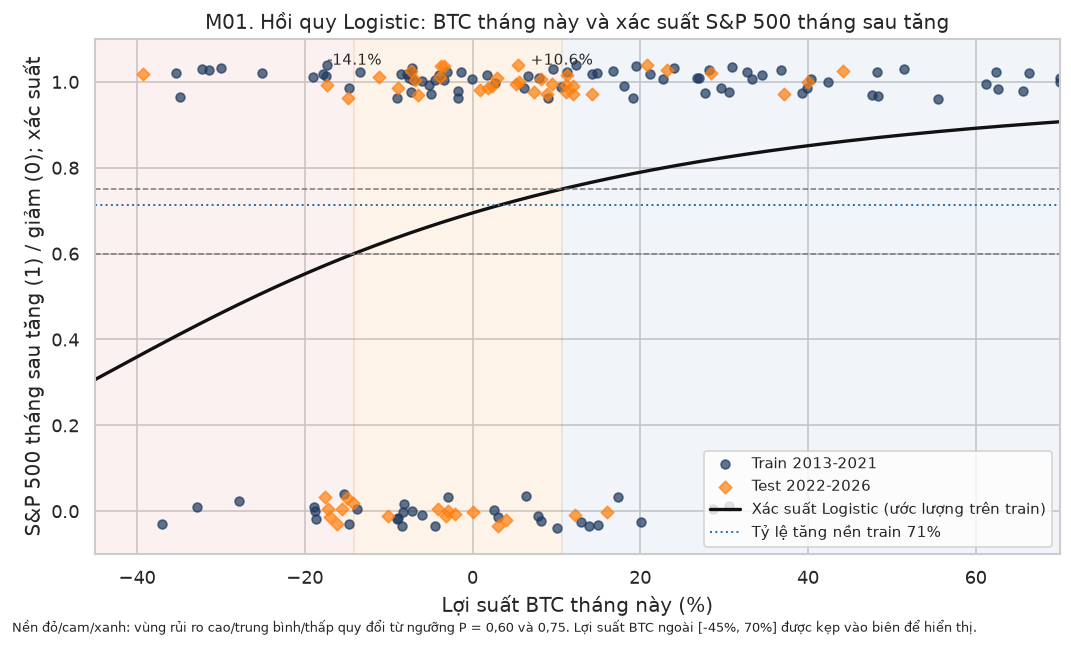

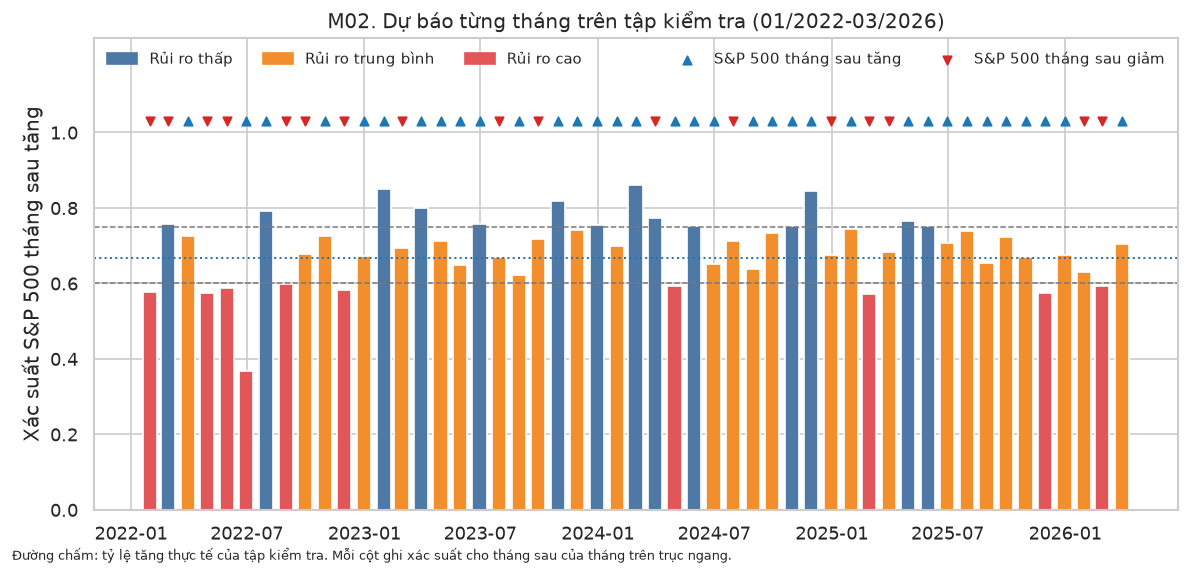

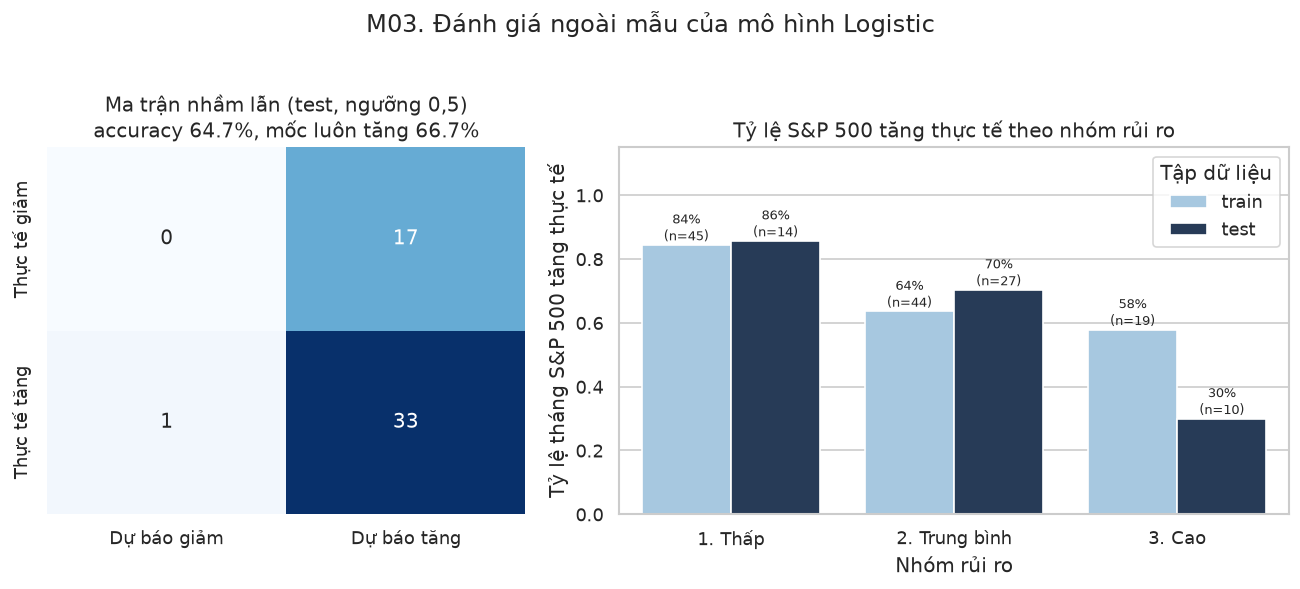

In [6]:
rng = np.random.default_rng(9)
fig, ax = plt.subplots(figsize=(9, 5.4))
grid_r = np.linspace(-45, 70, 400)
grid_p = 1 / (1 + np.exp(-(b0 + b1 * np.log1p(grid_r / 100))))
r_lo, r_hi = thresholds["p_0.60"]["btc_return_pct"], thresholds["p_0.75"]["btc_return_pct"]
ax.axvspan(grid_r.min(), r_lo, color=TIER_COLORS["3. Cao"], alpha=.08)
ax.axvspan(r_lo, r_hi, color=TIER_COLORS["2. Trung bình"], alpha=.10)
ax.axvspan(r_hi, grid_r.max(), color=TIER_COLORS["1. Thấp"], alpha=.08)
for name, frame, marker, color in [("Train 2013-2021", train, "o", "#1F3A5F"), ("Test 2022-2026", test, "D", "#FF7F0E")]:
    r = frame["btc_return_pct"].clip(grid_r.min(), grid_r.max())
    ax.scatter(r, frame["y_sp500_next_up"] + rng.uniform(-.04, .04, len(frame)), s=28, marker=marker,
               color=color, alpha=.7, label=name)
ax.plot(grid_r, grid_p, color="#111111", linewidth=2, label="Xác suất Logistic (ước lượng trên train)")
for p_cut in TIER_CUTS:
    ax.axhline(p_cut, color="#777777", linestyle="--", linewidth=.9)
ax.axhline(base_rate, color="#1F77B4", linestyle=":", linewidth=1.2, label=f"Tỷ lệ tăng nền train {base_rate:.0%}")
ax.set_xlim(grid_r.min(), grid_r.max()); ax.set_ylim(-.1, 1.1)
ax.set_xlabel("Lợi suất BTC tháng này (%)"); ax.set_ylabel("S&P 500 tháng sau tăng (1) / giảm (0); xác suất")
ax.set_title("M01. Hồi quy Logistic: BTC tháng này và xác suất S&P 500 tháng sau tăng")
ax.text(r_lo, 1.04, f"{r_lo:+.1f}%", ha="center", fontsize=9); ax.text(r_hi, 1.04, f"{r_hi:+.1f}%", ha="center", fontsize=9)
ax.legend(loc="lower right", fontsize=9)
fig.text(.01, .01, "Nền đỏ/cam/xanh: vùng rủi ro cao/trung bình/thấp quy đổi từ ngưỡng P = 0,60 và 0,75. Lợi suất BTC ngoài [-45%, 70%] được kẹp vào biên để hiển thị.", fontsize=8)
save(fig, "M01_duong_logistic.png")

fig, ax = plt.subplots(figsize=(10, 4.8))
colors = test["risk_tier"].map(TIER_COLORS)
ax.bar(test["month"], test["p_sp500_next_up"], width=22, color=colors)
for p_cut in TIER_CUTS:
    ax.axhline(p_cut, color="#777777", linestyle="--", linewidth=.9)
ax.axhline(test["y_sp500_next_up"].mean(), color="#1F77B4", linestyle=":", linewidth=1.2)
up = test["y_sp500_next_up"].eq(1)
ax.scatter(test.loc[up, "month"], np.full(up.sum(), 1.03), marker="^", color="#1F77B4", s=26, label="S&P 500 tháng sau tăng")
ax.scatter(test.loc[~up, "month"], np.full((~up).sum(), 1.03), marker="v", color="#D62728", s=26, label="S&P 500 tháng sau giảm")
ax.set_ylim(0, 1.25); ax.set_yticks(np.arange(0, 1.01, .2)); ax.set_ylabel("Xác suất S&P 500 tháng sau tăng")
ax.set_title("M02. Dự báo từng tháng trên tập kiểm tra (01/2022-03/2026)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in TIER_COLORS.values()]
leg1 = ax.legend(handles, [f"Rủi ro {k[3:].lower()}" for k in TIER_COLORS], loc="upper left", fontsize=9, ncol=3, frameon=False)
ax.add_artist(leg1); ax.legend(loc="upper right", fontsize=9, ncol=2, frameon=False)
fig.text(.01, .01, "Đường chấm: tỷ lệ tăng thực tế của tập kiểm tra. Mỗi cột ghi xác suất cho tháng sau của tháng trên trục ngang.", fontsize=8)
save(fig, "M02_du_bao_theo_thang_test.png")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), gridspec_kw={"width_ratios": [1, 1.4]})
m = evaluation["test"]["model"]
cm = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Dự báo giảm", "Dự báo tăng"], yticklabels=["Thực tế giảm", "Thực tế tăng"])
axes[0].set_title(f"Ma trận nhầm lẫn (test, ngưỡng 0,5)\naccuracy {m['accuracy']:.1%}, mốc luôn tăng {evaluation['test']['baseline_always_up']['accuracy']:.1%}")
plot_tiers = tiers.reset_index()
sns.barplot(data=plot_tiers, x="nhom", y="ty_le_sp500_tang", hue="tap", palette={"train": "#9ECAE9", "test": "#1F3A5F"}, ax=axes[1])
for bar_container, (_, sub) in zip(axes[1].containers, plot_tiers.groupby("tap", sort=False)):
    labels = [f"{v:.0%}\n(n={int(n)})" for v, n in zip(sub["ty_le_sp500_tang"], sub["so_thang"])]
    axes[1].bar_label(bar_container, labels=labels, fontsize=8)
axes[1].set_ylim(0, 1.15); axes[1].set_xlabel("Nhóm rủi ro"); axes[1].set_ylabel("Tỷ lệ tháng S&P 500 tăng thực tế")
axes[1].set_title("Tỷ lệ S&P 500 tăng thực tế theo nhóm rủi ro")
axes[1].legend(title="Tập dữ liệu", loc="upper right")
fig.suptitle("M03. Đánh giá ngoài mẫu của mô hình Logistic", y=1.02)
save(fig, "M03_danh_gia_test.png")

## Kiểm tra độ vững: quy ước thời điểm đo

`btc_return_pct` so sánh giá BTC **cuối** hai tháng liên tiếp, còn `sp500_return_pct` so sánh hai **mức tháng** của nguồn S&P 500 (phần lịch sử Shiller là trung bình giá đóng cửa trong tháng). Khi đó thay đổi S&P 500 "tháng sau" (trung bình tháng $t+1$ so với trung bình tháng $t$) đã chứa một phần diễn biến của nửa cuối tháng $t$ — cùng giai đoạn với lợi suất BTC tháng $t$. Liên hệ trễ một tháng có thể bị phóng đại bởi cách đo chứ không phải vì BTC đi trước.

Để kiểm tra, notebook tính thêm lợi suất BTC theo **giá trung bình tháng** từ `fact_crypto_daily`, đưa BTC về cùng quy ước với S&P 500, rồi so sánh tương quan cùng tháng và trễ một tháng, và ước lượng lại mô hình Logistic với biến mới.

,cua_so,cach_do_btc,so_sanh,n,pearson_r,p_value
0,01/2013-04/2026,BTC cuối tháng (đang dùng),cùng tháng,160,0.168,0.034
1,01/2013-04/2026,BTC cuối tháng (đang dùng),S&P tháng sau,159,0.175,0.027
2,01/2013-04/2026,BTC trung bình tháng,cùng tháng,160,0.272,0.001
3,01/2013-04/2026,BTC trung bình tháng,S&P tháng sau,159,0.118,0.137
4,01/2018-04/2026,BTC cuối tháng (đang dùng),cùng tháng,100,0.201,0.045
5,01/2018-04/2026,BTC cuối tháng (đang dùng),S&P tháng sau,99,0.390,0.000
6,01/2018-04/2026,BTC trung bình tháng,cùng tháng,100,0.437,0.000
7,01/2018-04/2026,BTC trung bình tháng,S&P tháng sau,99,0.130,0.198


Logistic với BTC trung bình tháng: b1 = 1.862 (p = 0.078); test accuracy 66.7%, AUC 0.651


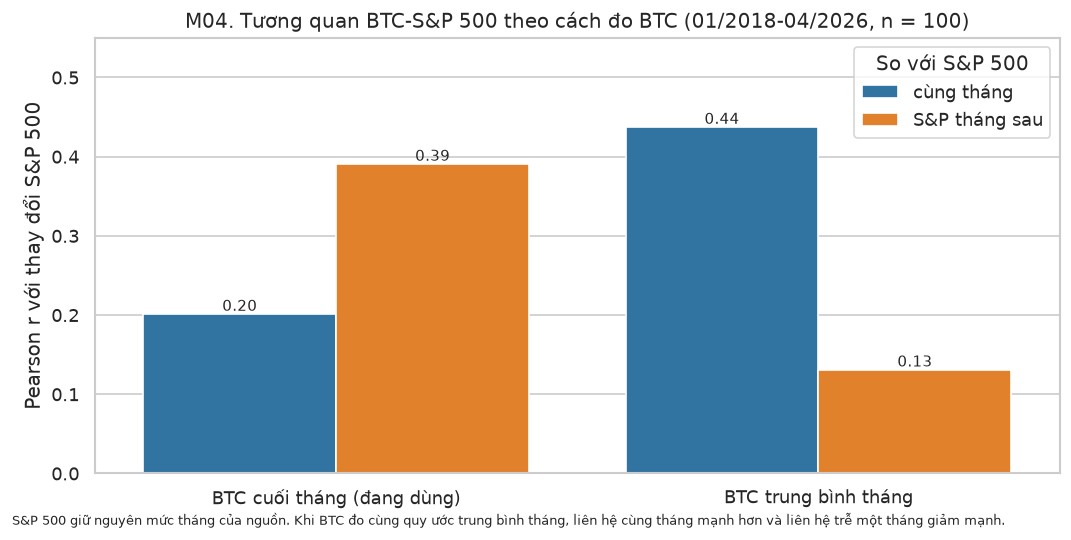

In [7]:
crypto = pd.read_csv(TABLES / "fact_crypto_daily.csv.gz", usecols=["date", "ticker", "price_usd"], parse_dates=["date"])
btc_avg = crypto.loc[crypto["ticker"].eq("BTC")].set_index("date")["price_usd"].resample("ME").mean()
df["btc_avg_return_pct"] = (btc_avg.pct_change(fill_method=None) * 100).reindex(df["month"]).to_numpy()

rows = []
for window, start in [("01/2013-04/2026", "2013-01-31"), ("01/2018-04/2026", "2018-01-31")]:
    w = df.loc[df["month"].ge(start)]
    for label, col in [("BTC cuối tháng (đang dùng)", "btc_return_pct"), ("BTC trung bình tháng", "btc_avg_return_pct")]:
        for lag_label, target in [("cùng tháng", w["sp500_return_pct"]), ("S&P tháng sau", w["sp500_next_return_pct"])]:
            pair = pd.concat([w[col], target], axis=1).dropna()
            r, p = stats.pearsonr(pair.iloc[:, 0], pair.iloc[:, 1])
            rows.append({"cua_so": window, "cach_do_btc": label, "so_sanh": lag_label, "n": len(pair), "pearson_r": r, "p_value": p})
timing = pd.DataFrame(rows)
display(timing.round(3))

alt = df.dropna(subset=["btc_avg_return_pct", "y_sp500_next_up"]).copy()
alt["x_avg"] = np.log1p(alt["btc_avg_return_pct"] / 100)
alt_train, alt_test = alt.loc[alt["split"].eq("train")], alt.loc[alt["split"].eq("test")]
logit_alt = sm.Logit(alt_train["y_sp500_next_up"].astype(int), sm.add_constant(alt_train[["x_avg"]])).fit(disp=0)
p_alt = logit_alt.predict(sm.add_constant(alt_test[["x_avg"]]))
alt_eval = {**classification_metrics(alt_test["y_sp500_next_up"], (p_alt >= .5).astype(int)),
            "auc": auc_rank(alt_test["y_sp500_next_up"], p_alt), "b1": float(logit_alt.params["x_avg"]),
            "b1_p_value": float(logit_alt.pvalues["x_avg"]), "n_train": int(len(alt_train)), "n_test": int(len(alt_test))}
print(f"Logistic với BTC trung bình tháng: b1 = {alt_eval['b1']:.3f} (p = {alt_eval['b1_p_value']:.3f}); test accuracy {alt_eval['accuracy']:.1%}, AUC {alt_eval['auc']:.3f}")

fig, ax = plt.subplots(figsize=(9, 4.5))
plot = timing.loc[timing["cua_so"].eq("01/2018-04/2026")]
sns.barplot(data=plot, x="cach_do_btc", y="pearson_r", hue="so_sanh", palette={"cùng tháng": "#1F77B4", "S&P tháng sau": "#FF7F0E"}, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=9)
ax.axhline(0, color="#555555", linewidth=.8)
ax.set_ylim(0, .55); ax.set_xlabel(""); ax.legend(title="So với S&P 500"); ax.set_ylabel("Pearson r với thay đổi S&P 500")
ax.set_title("M04. Tương quan BTC-S&P 500 theo cách đo BTC (01/2018-04/2026, n = 100)")
fig.text(.01, .01, "S&P 500 giữ nguyên mức tháng của nguồn. Khi BTC đo cùng quy ước trung bình tháng, liên hệ cùng tháng mạnh hơn và liên hệ trễ một tháng giảm mạnh.", fontsize=8)
save(fig, "M04_do_vung_quy_uoc_thoi_diem.png")

## Đối chiếu với workbook Tableau và lưu kết quả

Workbook `Crypto_Macro_Dashboard.twbx` nhập trực tiếp hệ số Logistic và các giá trị "tháng sau" vào calculated field (hàm `CASE [month] WHEN ... THEN ...`). Ô dưới đọc công thức trong workbook và so với giá trị tính lại từ bảng phân tích để bảo đảm hai nơi dùng cùng một số liệu: mỗi giá trị "tháng sau" phải bằng giá trị của tháng kế tiếp chia 100.

Kết quả được lưu vào:

- `data/processed/quality_reports/model_logistic_results.json`: hệ số, ngưỡng, chỉ số đánh giá, kiểm tra độ vững.
- `data/processed/tables/model_logistic_predictions.csv`: dự báo từng tháng, nhóm rủi ro và tập dữ liệu.
- `data/processed/model_figures/M01–M04`.

In [8]:
twbx = ROOT / "Crypto_Macro_Dashboard.twbx"
checks = []
if twbx.exists():
    with zipfile.ZipFile(twbx) as z:
        twb = z.read(next(n for n in z.namelist() if n.endswith(".twb"))).decode("utf-8")
    m = re.search(r"EXP\(-\(([0-9.]+) \+ ([0-9.]+) \* \[f_x\]\)\)", twb)
    assert m, "Không tìm thấy công thức Logistic trong workbook"
    assert np.isclose(float(m.group(1)), b0, atol=5e-7) and np.isclose(float(m.group(2)), b1, atol=5e-7)
    checks.append({"field": "f_p (hệ số Logistic)", "values": 2, "max_abs_diff": max(abs(float(m.group(1)) - b0), abs(float(m.group(2)) - b1))})
    next_fields = {"nx_sp500": "sp500_return_pct", "nx_gold": "gold_return_pct", "nx_vix": "vix_change_pct",
                   "nx_dxy": "dxy_return_pct", "nx_brent": "brent_return_pct", "nx_us10y": "us10y_change_pp",
                   "nx_cpi": "cpi_yoy_change_pp", "nx_real": "real_rate_change_pp"}
    for field, source in next_fields.items():
        formula = re.search(rf"name='\[{field}\]'[^>]*>\s*<calculation class='tableau' formula='([^']*)'", twb).group(1)
        pairs = re.findall(r"WHEN #(\d{4}-\d{2}-\d{2})# THEN (-?[0-9.]+)", formula)
        tableau = pd.Series({pd.Timestamp(d): float(v) for d, v in pairs})
        expected_next = (data.set_index("month")[source].shift(-1) / 100).reindex(tableau.index)
        assert expected_next.notna().all(), f"{field}: Tableau có giá trị ở tháng mà bảng phân tích không có"
        diff = (tableau - expected_next).abs()
        assert diff.max() < 1e-7, f"{field} lệch {diff.max()}"
        checks.append({"field": field, "values": len(tableau), "max_abs_diff": float(diff.max())})
display(pd.DataFrame(checks))

predictions = df[["month", "btc_price_usd", "btc_return_pct", "x_log_btc", "sp500_next_return_pct",
                  "y_sp500_next_up", "p_sp500_next_up", "risk_tier", "split"]].copy()
predictions.loc[predictions["y_sp500_next_up"].isna(), "split"] = "forecast"
write_csv_atomic(predictions, TABLES / "model_logistic_predictions.csv")

results = {
    "data": {"table": "analysis_crypto_macro_monthly.csv", "months": int(len(df)), "model_months": int(len(model_df)),
             "train": [str(train.month.min().date()), str(train.month.max().date()), int(len(train))],
             "test": [str(test.month.min().date()), str(test.month.max().date()), int(len(test))],
             "train_up_rate": base_rate, "test_up_rate": float(test["y_sp500_next_up"].mean())},
    "coefficients": coef_table.reset_index(names="term").to_dict(orient="records"),
    "odds_ratio_btc_plus_10pct": {"value": or_10pct, "ci95": or_10pct_ci},
    "p_when_btc_flat": p_flat,
    "mcfadden_pseudo_r2": float(logit.prsquared), "llr_p_value": float(logit.llr_pvalue),
    "tier_thresholds": thresholds,
    "tiers": tiers.reset_index().to_dict(orient="records"),
    "evaluation": evaluation,
    "fisher_low_vs_high_test": {"odds_ratio": float(fisher.statistic), "p_value": float(fisher.pvalue)},
    "yearly": yearly.reset_index().to_dict(orient="records"),
    "one_step_forecast": {"month": str(latest.month.date()), "btc_return_pct": float(latest.btc_return_pct),
                          "p_sp500_next_up": float(latest.p_sp500_next_up), "risk_tier": latest.risk_tier},
    "timing_robustness": {"correlations": timing.to_dict(orient="records"), "logit_btc_monthly_average": alt_eval},
    "tableau_consistency": checks,
    "interpretation_limit": "Contemporaneous/lagged statistical association on monthly data; not causal; not a trading rule.",
}
write_json_atomic(results, QUALITY / "model_logistic_results.json")
print("Đã lưu kết quả mô hình và", len(list(MODEL_FIG.glob("M*.png"))), "hình.")

,field,values,max_abs_diff
0,f_p (hệ số Logistic),2,3.598272e-07
1,nx_sp500,159,4.948171e-09
2,nx_gold,159,4.981468e-09
3,nx_vix,159,4.988210e-09
4,nx_dxy,159,4.988982e-09
5,nx_brent,159,4.993447e-09
6,nx_us10y,159,8.023096e-18
7,nx_cpi,157,4.998905e-09
8,nx_real,157,4.998905e-09


Đã lưu kết quả mô hình và 4 hình.
